In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [5]:
import pandas as pd

df = pd.read_csv("data/train.csv")

df.head()

,Id,MSSubClass,MSZoning,LotFrontage,LotArea,Street,Alley,LotShape,LandContour,Utilities,...,PoolArea,PoolQC,Fence,MiscFeature,MiscVal,MoSold,YrSold,SaleType,SaleCondition,SalePrice
0,1,60,RL,65.0,8450,Pave,NaN,Reg,Lvl,AllPub,...,0,NaN,NaN,NaN,0,2,2008,WD,Normal,208500
1,2,20,RL,80.0,9600,Pave,NaN,Reg,Lvl,AllPub,...,0,NaN,NaN,NaN,0,5,2007,WD,Normal,181500
2,3,60,RL,68.0,11250,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,NaN,NaN,0,9,2008,WD,Normal,223500
3,4,70,RL,60.0,9550,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,NaN,NaN,0,2,2006,WD,Abnorml,140000
4,5,60,RL,84.0,14260,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,NaN,NaN,0,12,2008,WD,Normal,250000


In [6]:
df.shape

(1460, 81)

In [7]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 1460 entries, 0 to 1459
Data columns (total 81 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   Id             1460 non-null   int64  
 1   MSSubClass     1460 non-null   int64  
 2   MSZoning       1460 non-null   str    
 3   LotFrontage    1201 non-null   float64
 4   LotArea        1460 non-null   int64  
 5   Street         1460 non-null   str    
 6   Alley          91 non-null     str    
 7   LotShape       1460 non-null   str    
 8   LandContour    1460 non-null   str    
 9   Utilities      1460 non-null   str    
 10  LotConfig      1460 non-null   str    
 11  LandSlope      1460 non-null   str    
 12  Neighborhood   1460 non-null   str    
 13  Condition1     1460 non-null   str    
 14  Condition2     1460 non-null   str    
 15  BldgType       1460 non-null   str    
 16  HouseStyle     1460 non-null   str    
 17  OverallQual    1460 non-null   int64  
 18  OverallCond    1460

In [8]:
df["SalePrice"].describe()

count      1460.000000
mean     180921.195890
std       79442.502883
min       34900.000000
25%      129975.000000
50%      163000.000000
75%      214000.000000
max      755000.000000
Name: SalePrice, dtype: float64

In [9]:
missing = df.isnull().sum()

missing = missing[missing > 0].sort_values(ascending=False)

print(missing)

PoolQC          1453
MiscFeature     1406
Alley           1369
Fence           1179
MasVnrType       872
FireplaceQu      690
LotFrontage      259
GarageType        81
GarageYrBlt       81
GarageFinish      81
GarageQual        81
GarageCond        81
BsmtExposure      38
BsmtFinType2      38
BsmtQual          37
BsmtCond          37
BsmtFinType1      37
MasVnrArea         8
Electrical         1
dtype: int64


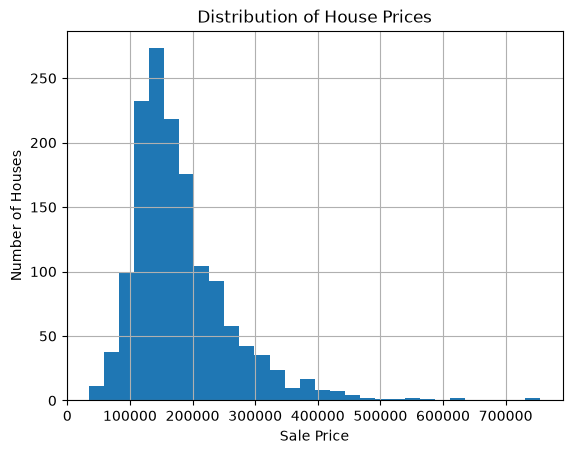

In [10]:
df["SalePrice"].hist(bins=30)

plt.xlabel("Sale Price")
plt.ylabel("Number of Houses")
plt.title("Distribution of House Prices")

plt.show()

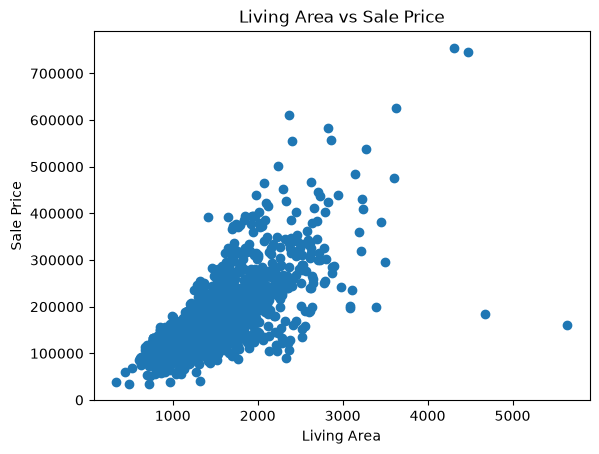

In [11]:
plt.scatter(df["GrLivArea"], df["SalePrice"])

plt.xlabel("Living Area")
plt.ylabel("Sale Price")
plt.title("Living Area vs Sale Price")

plt.show()

In [13]:
features = [
    "GrLivArea",
    "BedroomAbvGr",
    "FullBath",
    "HalfBath",
    "OverallQual",
    "YearBuilt",
    "GarageCars",
    "TotalBsmtSF"
]

In [14]:
X = df[features]
y = df["SalePrice"]

In [15]:
X.isnull().sum()

GrLivArea       0
BedroomAbvGr    0
FullBath        0
HalfBath        0
OverallQual     0
YearBuilt       0
GarageCars      0
TotalBsmtSF     0
dtype: int64

In [18]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42
)

   ---------------------------------------- 0.0/8.2 MB ? eta -:--:--
   ---------------------------------------- 0.0/8.2 MB ? eta -:--:--
   - -------------------------------------- 0.3/8.2 MB ? eta -:--:--
   - -------------------------------------- 0.3/8.2 MB ? eta -:--:--
   -- ------------------------------------- 0.5/8.2 MB 538.0 kB/s eta 0:00:15
   -- ------------------------------------- 0.5/8.2 MB 538.0 kB/s eta 0:00:15
   --- ------------------------------------ 0.8/8.2 MB 695.5 kB/s eta 0:00:11
   --- ------------------------------------ 0.8/8.2 MB 695.5 kB/s eta 0:00:11
   --- ------------------------------------ 0.8/8.2 MB 695.5 kB/s eta 0:00:11
   --- ------------------------------------ 0.8/8.2 MB 695.5 kB/s eta 0:00:11
   --- ------------------------------------ 0.8/8.2 MB 695.5 kB/s eta 0:00:11
   ----- ---------------------------------- 1.0/8.2 MB 389.9 kB/s eta 0:00:19
   ----- ---------------------------------- 1.0/8.2 MB 389.9 kB/s eta 0:00:19
   ----- -------------

In [19]:
from sklearn.linear_model import LinearRegression

model = LinearRegression()

model.fit(X_train, y_train)

,"fit_intercept fit_intercept: bool, default=TrueWhether to calculate the intercept for this model. If setto False, no intercept will be used in calculations(i.e. data is expected to be centered).",True
,"copy_X copy_X: bool, default=TrueIf True, X will be copied; else, it may be overwritten.",True
,"tol tol: float, default=1e-6The precision of the solution (`coef_`) is determined by `tol` whichspecifies the convergence criterion of the underlying solver. `tol` isset as `atol` and `btol` of :func:`scipy.sparse.linalg.lsqr` whenfitting on sparse training data. `tol` is set as `cond` of:func:`scipy.linalg.lstsq` when fitting on dense training data... versionadded:: 1.7.. versionchanged:: 1.9 Now supported on dense data, interpreted as the `cond` parameter.",1e-06
,"n_jobs n_jobs: int, default=NoneThe number of jobs to use for the computation. This will only providespeedup in case of sufficiently large problems, that is if firstly`n_targets > 1` and secondly `X` is sparse or if `positive` is setto `True`. ``None`` means 1 unless in a:obj:`joblib.parallel_backend` context. ``-1`` means using allprocessors. See :term:`Glossary <n_jobs>` for more details.",None
,"positive positive: bool, default=FalseWhen set to ``True``, forces the coefficients to be positive. Thisoption is only supported for dense arrays.For a comparison between a linear regression model with positive constraintson the regression coefficients and a linear regression without such constraints,see :ref:`sphx_glr_auto_examples_linear_model_plot_nnls.py`... versionadded:: 0.24",False
Name,Type,Value
"coef_ coef_: array of shape (n_features, ) or (n_targets, n_features)Estimated coefficients for the linear regression problem.If multiple targets are passed during the fit (y 2D), thisis a 2D array of shape (n_targets, n_features), while if onlyone target is passed, this is a 1D array of length n_features.","ndarray[float64](8,)","[ 60.56,-6648.31,-4673.14,..., 361.02,14693.81, 21.69]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Defined only when `X`has feature names that are all strings... versionadded:: 1.0","ndarray[object](8,)","['GrLivArea','BedroomAbvGr','FullBath',...,'YearBuilt','GarageCars', 'TotalBsmtSF']"
"intercept_ intercept_: float or array of shape (n_targets,)Independent term in the linear model. Set to 0.0 if`fit_intercept = False`.",float64,-7.64e+05
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`... versionadded:: 0.24,int,8
rank_ rank_: intRank of matrix `X`. Only available when `X` is dense.,int64,np.int64(8)


In [20]:
y_pred = model.predict(X_test)

In [21]:
print("Actual:", y_test.iloc[0])
print("Predicted:", y_pred[0])

Actual: 154500
Predicted: 139806.8949768272


In [22]:
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

In [23]:
mae = mean_absolute_error(y_test, y_pred)

mse = mean_squared_error(y_test, y_pred)

rmse = np.sqrt(mse)

r2 = r2_score(y_test, y_pred)

print("MAE:", mae)
print("RMSE:", rmse)
print("R² Score:", r2)

MAE: 24977.82273807092
RMSE: 39006.9992318853
R² Score: 0.8016321668756923


In [24]:
from sklearn.ensemble import RandomForestRegressor

rf_model = RandomForestRegressor(
    n_estimators=300,
    random_state=42
)

rf_model.fit(X_train, y_train)

rf_pred = rf_model.predict(X_test)

rf_r2 = r2_score(y_test, rf_pred)

print("Random Forest R²:", rf_r2)

Random Forest R²: 0.8915460696681541


In [25]:
importance = pd.Series(
    rf_model.feature_importances_,
    index=features
).sort_values(ascending=False)

print(importance)

OverallQual     0.581959
GrLivArea       0.193117
TotalBsmtSF     0.108393
YearBuilt       0.056178
GarageCars      0.031249
BedroomAbvGr    0.012715
FullBath        0.012426
HalfBath        0.003964
dtype: float64


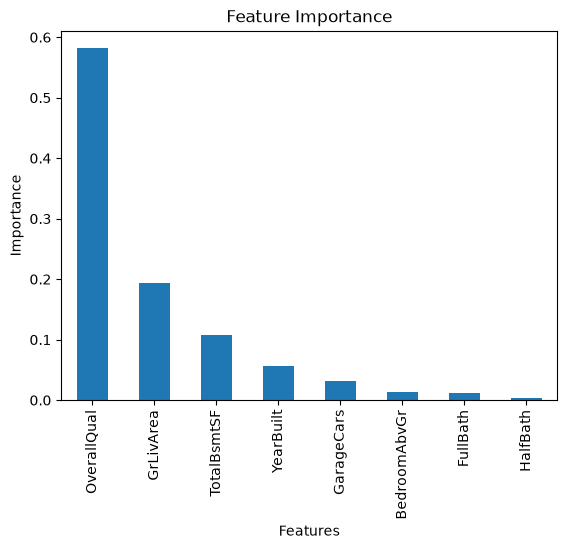

In [26]:
importance.plot(kind="bar")

plt.title("Feature Importance")
plt.xlabel("Features")
plt.ylabel("Importance")

plt.show()

In [28]:
import joblib

joblib.dump(model, "models/house_price_model.pkl")

['models/house_price_model.pkl']

In [2]:
import joblib

model = joblib.load("models/house_price_model.pkl")

print("Model loaded successfully!")

Model loaded successfully!


In [3]:
features = [
    "GrLivArea",
    "BedroomAbvGr",
    "FullBath",
    "HalfBath",
    "OverallQual",
    "YearBuilt",
    "GarageCars",
    "TotalBsmtSF"
]

In [4]:
new_house = [[
    2000,   # GrLivArea
    3,      # BedroomAbvGr
    2,      # FullBath
    1,      # HalfBath
    7,      # OverallQual
    2015,   # YearBuilt
    2,      # GarageCars
    800     # TotalBsmtSF
]]

In [5]:
predicted_price = model.predict(new_house)

print("Predicted House Price:", predicted_price[0])

Predicted House Price: 236321.28996331908


c:\Users\HP\OneDrive\Desktop\House Price Prediction\venv\Lib\site-packages\sklearn\utils\validation.py:2830: UserWarning: X does not have valid feature names, but LinearRegression was fitted with feature names
  warnings.warn(


In [6]:
print(f"Predicted House Price: ${predicted_price[0]:,.2f}")

Predicted House Price: $236,321.29
